# BÀI TẬP LỚN: XẤP XỈ HÀM SỐ DÙNG MẠNG MLP (PYTORCH)

Notebook này triển khai đầy đủ quy trình bài tập lớn môn **Học sâu (Deep Learning)**:
1. **Sinh, lưu và khảo sát dữ liệu**: Tính hàm mật độ xác suất Gaussian hai chiều theo công thức toán học, chia tập `train` / `validation` / `test` độc lập với `seed` cố định, chuẩn hóa dữ liệu chống rò rỉ (Data Leakage) và trực quan hóa 3D.
2. **Thiết kế và huấn luyện mạng MLP bằng PyTorch**: Xây dựng lớp `DynamicMLP(nn.Module)` linh hoạt số tầng ẩn $C$, số nơ-ron mỗi tầng $B$ và hàm kích hoạt; tự xây dựng vòng lặp huấn luyện/đánh giá chuẩn mực và lưu checkpoint `.pt` tốt nhất theo `val_loss`.
3. **Ba nhóm thực nghiệm bắt buộc (A, B, C)**:
   - **Thực nghiệm A**: Đánh giá sai số theo quy mô mẫu huấn luyện $A \in \{200, 400, \dots, 2000\}$.
   - **Thực nghiệm B**: Đánh giá sai số theo độ rộng tầng ẩn $B \in \{1, 2, \dots, 10, 16, 32, 64, 128\}$ (nhận xét thiếu khớp / quá khớp).
   - **Thực nghiệm C**: Đánh giá sai số, tốc độ hội tụ và thời gian huấn luyện theo độ sâu $C \in \{1, 2, 3, 4, 6, 8\}$ tầng ẩn.

**Nguyên tắc đánh giá:** A/B/C chỉ dùng Train và Validation để so sánh cấu hình; Test được giữ riêng cho đánh giá mô hình cuối cùng.

## 0. Khai báo thư viện và cấu hình môi trường

In [7]:
import os
os.environ["KMP_DUPLICATE_LIB_OK"] = "TRUE"
os.environ["OMP_NUM_THREADS"] = "1"
import time
import random
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from mpl_toolkits.mplot3d import Axes3D

import torch
import torch.nn as nn
from torch.utils.data import TensorDataset, DataLoader

# Hiển thị đồ thị trực tiếp trong Notebook
%matplotlib inline

# Tạo các thư mục lưu trữ kết quả
for folder in ['data', 'checkpoints', 'logs', 'figures']:
    os.makedirs(folder, exist_ok=True)

# Hỗ trợ thiết bị CPU / GPU
DEVICE = torch.device('cuda' if torch.cuda.is_available() else 'cpu')
print(f"Đang sử dụng thiết bị: {DEVICE}")

def set_seed(seed=42):
    """Cố định random seed để tái lập kết quả thực nghiệm."""
    random.seed(seed)
    np.random.seed(seed)
    torch.manual_seed(seed)
    if torch.cuda.is_available():
        torch.cuda.manual_seed_all(seed)

Đang sử dụng thiết bị: cpu


## 1. Sinh, lưu và khảo sát dữ liệu (Mục 3.1)

Cho hàm mật độ Gaussian hai chiều:

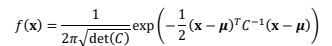

với:

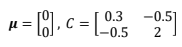

Miền giá trị: $-2 \le x_1 \le 2$, $-4 \le x_2 \le 4$.

In [8]:
def gaussian_2d_pdf(x, mu, cov):
    """
    Tính hàm mật độ Gaussian 2 chiều đúng theo công thức toán học:
    f(x) = 1 / (2*pi * sqrt(det(C))) * exp(-0.5 * (x - mu)^T * C^-1 * (x - mu))
    - x: mảng numpy kích thước (N, 2)
    """
    # Tính det(C) và C^-1 trực tiếp cho ma trận 2x2 để tránh lỗi crash BLAS/LAPACK trên Windows
    a, b = cov[0, 0], cov[0, 1]
    c, d = cov[1, 0], cov[1, 1]
    det_cov = a * d - b * c
    inv_cov = np.array([[d, -b], [-c, a]], dtype=np.float64) / det_cov
    
    norm_const = 1.0 / (2.0 * np.pi * np.sqrt(det_cov))
    
    diff = x - mu  # (N, 2)
    # Tính dạng toàn phương (x - mu)^T * C^-1 * (x - mu) cho từng mẫu
    quad_form = np.sum((diff @ inv_cov) * diff, axis=1)
    
    y = norm_const * np.exp(-0.5 * quad_form)
    return y

def generate_and_save_datasets(seed=42):
    """Sinh dữ liệu Train (pool 2000 mẫu), Validation (200 mẫu) và Test (100 mẫu) độc lập."""
    set_seed(seed)
    mu = np.array([0.0, 0.0])
    cov = np.array([[0.3, -0.5], [-0.5, 2.0]])
    r1 = (-2.0, 2.0)
    r2 = (-4.0, 4.0)

    def _sample(n_samples, filepath):
        x = np.zeros((n_samples, 2), dtype=np.float32)
        x[:, 0] = np.random.uniform(r1[0], r1[1], size=n_samples)
        x[:, 1] = np.random.uniform(r2[0], r2[1], size=n_samples)
        y = gaussian_2d_pdf(x, mu, cov).astype(np.float32)
        
        df = pd.DataFrame({'x1': x[:, 0], 'x2': x[:, 1], 'y': y})
        df.to_csv(filepath, index=False)
        return x, y

    x_train, y_train = _sample(2000, 'data/train_pool.csv')
    x_val, y_val     = _sample(200,  'data/val.csv')
    x_test, y_test   = _sample(100,  'data/test.csv')

    print("=== THỐNG KÊ DỮ LIỆU ĐÃ SINH ===")
    for name, x, y in [('Train Pool', x_train, y_train), ('Validation', x_val, y_val), ('Test', x_test, y_test)]:
        print(f"{name:10s} (N={len(x):4d}) | x1: [{x[:,0].min():.2f}, {x[:,0].max():.2f}] | "
              f"x2: [{x[:,1].min():.2f}, {x[:,1].max():.2f}] | y: [{y.min():.4f}, {y.max():.4f}], mean={y.mean():.4f}")
    
    return (x_train, y_train), (x_val, y_val), (x_test, y_test), mu, cov

(x_pool, y_pool), (x_val, y_val), (x_test, y_test), mu, cov = generate_and_save_datasets(seed=42)

=== THỐNG KÊ DỮ LIỆU ĐÃ SINH ===
Train Pool (N=2000) | x1: [-1.99, 2.00] | x2: [-4.00, 4.00] | y: [0.0000, 0.2686], mean=0.0305
Validation (N= 200) | x1: [-2.00, 1.98] | x2: [-3.83, 3.98] | y: [0.0000, 0.2495], mean=0.0305
Test       (N= 100) | x1: [-1.98, 1.99] | x2: [-3.95, 3.98] | y: [0.0000, 0.2604], mean=0.0336


### Trực quan hóa dữ liệu 3D và bề mặt hàm Gaussian thật

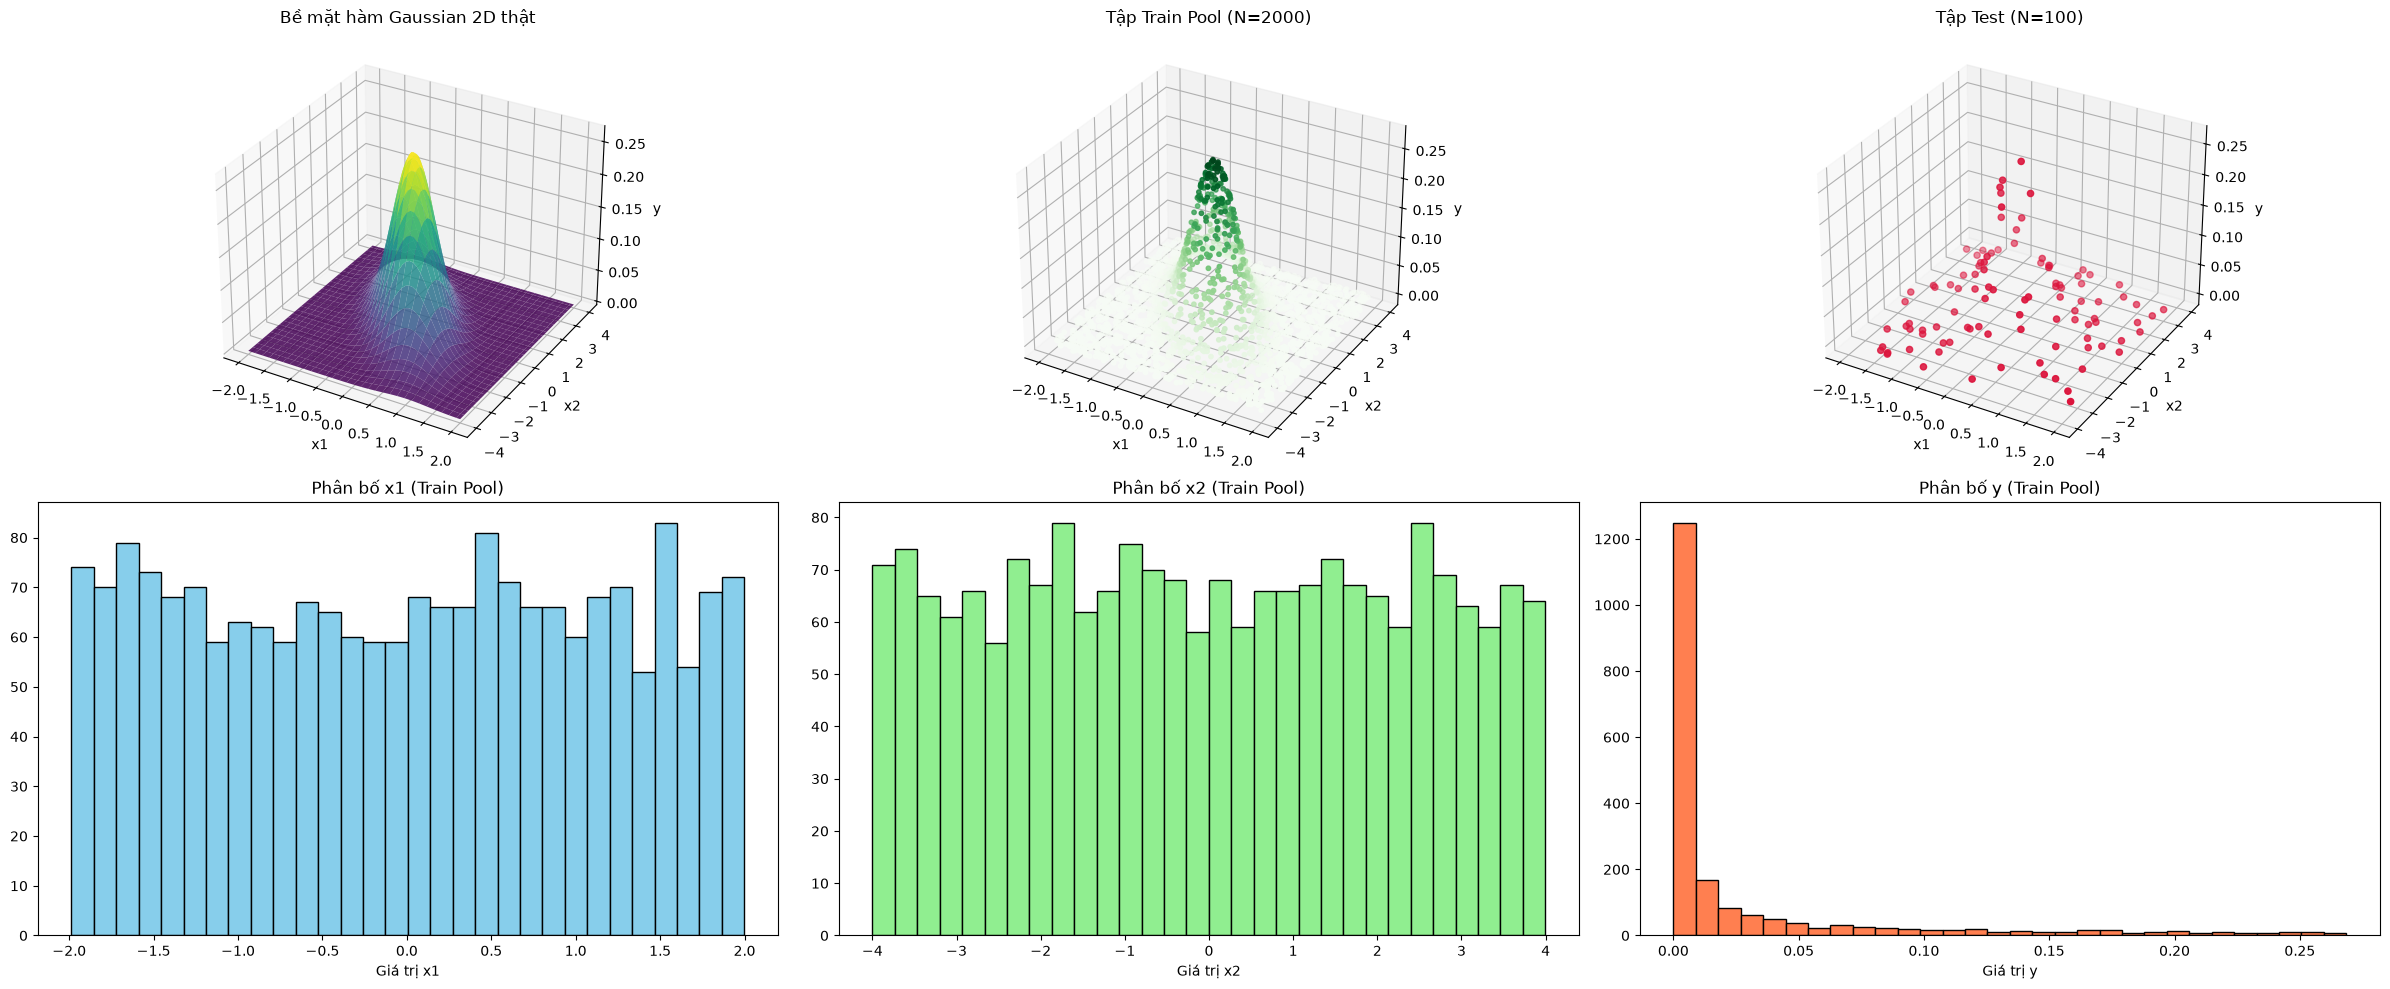


=== KIỂM TRA MIỀN GIÁ TRỊ TẬP TRAIN ===
x1 nằm trong [-2, 2]: -1.9871 đến 1.9989 -> PASS
x2 nằm trong [-4, 4]: -3.9999 đến 3.9965 -> PASS
y nằm trong [0, 1]: 0.0000 đến 0.2686 -> PASS

=== THỐNG KÊ CHI TIẾT TẬP TRAIN ===


,mean,std,min,max
x1,-0.005452,1.168843,-1.987127e+00,1.998871
x2,-0.028877,2.308639,-3.999907e+00,3.996462
y,0.030519,0.057824,4.796964e-13,0.268561


In [9]:
def plot_data_exploration(x_train, y_train, x_test, y_test, mu, cov):
    """Vẽ bề mặt hàm Gaussian thật, scatter 3D, và Histogram phân bố các biến."""
    fig = plt.figure(figsize=(24, 10))

    # 1. Bề mặt lý thuyết
    ax1 = fig.add_subplot(231, projection='3d')
    grid_x1, grid_x2 = np.meshgrid(np.linspace(-2, 2, 60), np.linspace(-4, 4, 60))
    grid_pts = np.column_stack([grid_x1.ravel(), grid_x2.ravel()])
    grid_y = gaussian_2d_pdf(grid_pts, mu, cov).reshape(grid_x1.shape)
    ax1.plot_surface(grid_x1, grid_x2, grid_y, cmap='viridis', alpha=0.85)
    ax1.set_title("Bề mặt hàm Gaussian 2D thật")
    ax1.set_xlabel("x1"); ax1.set_ylabel("x2"); ax1.set_zlabel("y")

    # 2. Scatter tập Train
    ax2 = fig.add_subplot(232, projection='3d')
    ax2.scatter(x_train[:, 0], x_train[:, 1], y_train, c=y_train, cmap='Greens', s=10)
    ax2.set_title(f"Tập Train Pool (N={len(x_train)})")
    ax2.set_xlabel("x1"); ax2.set_ylabel("x2"); ax2.set_zlabel("y")

    # 3. Scatter tập Test
    ax3 = fig.add_subplot(233, projection='3d')
    ax3.scatter(x_test[:, 0], x_test[:, 1], y_test, c='crimson', s=20)
    ax3.set_title(f"Tập Test (N={len(x_test)})")
    ax3.set_xlabel("x1"); ax3.set_ylabel("x2"); ax3.set_zlabel("y")
    
    # 4. Histogram phân bố x1
    ax4 = fig.add_subplot(234)
    ax4.hist(x_train[:, 0], bins=30, color='skyblue', edgecolor='black')
    ax4.set_title("Phân bố x1 (Train Pool)")
    ax4.set_xlabel("Giá trị x1")
    
    # 5. Histogram phân bố x2
    ax5 = fig.add_subplot(235)
    ax5.hist(x_train[:, 1], bins=30, color='lightgreen', edgecolor='black')
    ax5.set_title("Phân bố x2 (Train Pool)")
    ax5.set_xlabel("Giá trị x2")
    
    # 6. Histogram phân bố y
    ax6 = fig.add_subplot(236)
    ax6.hist(y_train, bins=30, color='coral', edgecolor='black')
    ax6.set_title("Phân bố y (Train Pool)")
    ax6.set_xlabel("Giá trị y")

    plt.tight_layout()
    plt.savefig('figures/01_data_exploration.png', dpi=150)
    plt.show()

def check_data_range(x_train, y_train):
    """Kiểm tra miền giá trị của dữ liệu so với yêu cầu."""
    print("\n=== KIỂM TRA MIỀN GIÁ TRỊ TẬP TRAIN ===")
    print(f"x1 nằm trong [-2, 2]: {x_train[:, 0].min():.4f} đến {x_train[:, 0].max():.4f} -> {'PASS' if x_train[:, 0].min() >= -2 and x_train[:, 0].max() <= 2 else 'FAIL'}")
    print(f"x2 nằm trong [-4, 4]: {x_train[:, 1].min():.4f} đến {x_train[:, 1].max():.4f} -> {'PASS' if x_train[:, 1].min() >= -4 and x_train[:, 1].max() <= 4 else 'FAIL'}")
    print(f"y nằm trong [0, 1]: {y_train.min():.4f} đến {y_train.max():.4f} -> {'PASS' if y_train.min() >= 0 and y_train.max() <= 1 else 'FAIL'}")
    
    print("\n=== THỐNG KÊ CHI TIẾT TẬP TRAIN ===")
    df = pd.DataFrame({'x1': x_train[:, 0], 'x2': x_train[:, 1], 'y': y_train})
    display(df.describe().T[['mean', 'std', 'min', 'max']])

plot_data_exploration(x_pool, y_pool, x_test, y_test, mu, cov)
check_data_range(x_pool, y_pool)

## 2. Thiết kế và huấn luyện mạng MLP bằng PyTorch (Mục 3.2)

Xây dựng lớp `DynamicMLP` kế thừa từ `torch.nn.Module`, cho phép tùy chỉnh số tầng ẩn và số nơ-ron mỗi tầng. Kèm theo đó là quy trình chuẩn hóa Z-score trên tập `train`, vòng lặp huấn luyện `DataLoader`, lưu checkpoint tốt nhất theo `val_loss` và tính các chỉ số đánh giá **MSE, RMSE, MAE**.

In [10]:
class DynamicMLP(nn.Module):
    """
    Mạng Perceptron Đa Tầng (MLP) tùy biến:
    - input_dim: số chiều đầu vào (2)
    - output_dim: số chiều đầu ra (1)
    - hidden_dims: danh sách số nơ-ron tại mỗi tầng ẩn, ví dụ [64, 64]
    - activation: 'relu', 'tanh', hoặc 'sigmoid'
    """
    def __init__(self, input_dim=2, output_dim=1, hidden_dims=[64], activation='tanh'):
        super(DynamicMLP, self).__init__()
        layers = []
        prev_dim = input_dim
        
        act_dict = {
            'relu': nn.ReLU,
            'tanh': nn.Tanh,
            'sigmoid': nn.Sigmoid
        }
        act_layer = act_dict.get(activation.lower(), nn.Tanh)

        for h_dim in hidden_dims:
            layers.append(nn.Linear(prev_dim, h_dim))
            layers.append(act_layer())
            prev_dim = h_dim
            
        # Tầng đầu ra tuyến tính cho bài toán hồi quy
        layers.append(nn.Linear(prev_dim, output_dim))
        self.network = nn.Sequential(*layers)

    def forward(self, x):
        return self.network(x)

def evaluate_metrics(model, x_tensor, y_tensor):
    """Đánh giá mô hình bằng MSE, RMSE và MAE."""
    model.eval()
    with torch.no_grad():
        preds = model(x_tensor.to(DEVICE)).cpu().numpy().flatten()
        targets = y_tensor.numpy().flatten()
        
    mse = np.mean((targets - preds) ** 2)
    rmse = np.sqrt(mse)
    mae = np.mean(np.abs(targets - preds))
    return {'MSE': mse, 'RMSE': rmse, 'MAE': mae, 'preds': preds}

def train_and_evaluate_mlp(
    x_train, y_train, x_val, y_val, x_test, y_test,
    hidden_dims=[64], activation='tanh', lr=0.005, batch_size=32, epochs=150,
    seed=42, exp_name='baseline', save_log=True, evaluate_test=False
):
    """Quy trình chuẩn hóa dữ liệu, huấn luyện, lưu checkpoint và đánh giá."""
    set_seed(seed)
    
    # Chuẩn hóa Z-score dựa trên tập Train (Tránh Data Leakage)
    mean = x_train.mean(axis=0, keepdims=True)
    std = x_train.std(axis=0, keepdims=True) + 1e-8
    
    x_tr_norm = torch.tensor((x_train - mean) / std, dtype=torch.float32)
    y_tr_t    = torch.tensor(y_train.reshape(-1, 1), dtype=torch.float32)
    x_va_norm = torch.tensor((x_val - mean) / std, dtype=torch.float32)
    y_va_t    = torch.tensor(y_val.reshape(-1, 1), dtype=torch.float32)
    # Chỉ chuẩn bị Test khi được yêu cầu (baseline/final evaluation).
    x_te_norm = y_te_t = None
    if evaluate_test:
        if x_test is None or y_test is None:
            raise ValueError("Cần truyền x_test và y_test khi evaluate_test=True.")
        x_te_norm = torch.tensor((x_test - mean) / std, dtype=torch.float32)
        y_te_t = torch.tensor(y_test.reshape(-1, 1), dtype=torch.float32)

    train_loader = DataLoader(TensorDataset(x_tr_norm, y_tr_t), batch_size=batch_size, shuffle=True)
    
    model = DynamicMLP(2, 1, hidden_dims=hidden_dims, activation=activation).to(DEVICE)
    criterion = nn.MSELoss()
    optimizer = torch.optim.Adam(model.parameters(), lr=lr)

    best_val_loss = float('inf')
    best_epoch = 0
    ckpt_path = f"checkpoints/{exp_name}_seed{seed}.pt"
    history = []

    start_time = time.time()
    for epoch in range(1, epochs + 1):
        # 1. Huấn luyện (Train mode)
        model.train()
        for bx, by in train_loader:
            bx, by = bx.to(DEVICE), by.to(DEVICE)
            preds = model(bx)
            loss = criterion(preds, by)
            
            optimizer.zero_grad()
            loss.backward()
            optimizer.step()

        # 2. Đánh giá cuối mỗi epoch trên toàn tập Train & Val (Eval mode)
        model.eval()
        with torch.no_grad():
            tr_loss = criterion(model(x_tr_norm.to(DEVICE)), y_tr_t.to(DEVICE)).item()
            va_loss = criterion(model(x_va_norm.to(DEVICE)), y_va_t.to(DEVICE)).item()

        history.append({'epoch': epoch, 'train_mse': tr_loss, 'val_mse': va_loss})

        # Lưu checkpoint tốt nhất theo Validation Loss
        if va_loss < best_val_loss:
            best_val_loss = va_loss
            best_epoch = epoch
            torch.save({
                'model_state_dict': model.state_dict(),
                'mean': mean,
                'std': std,
                'hidden_dims': hidden_dims,
                'activation': activation
            }, ckpt_path)

    train_time = time.time() - start_time

    if save_log:
        pd.DataFrame(history).to_csv(f"logs/history_{exp_name}_seed{seed}.csv", index=False)

    # Khôi phục mô hình tốt nhất từ checkpoint để đánh giá
    ckpt = torch.load(ckpt_path, map_location=DEVICE, weights_only=False)
    model.load_state_dict(ckpt['model_state_dict'])

    tr_metrics = evaluate_metrics(model, x_tr_norm, y_tr_t)
    va_metrics = evaluate_metrics(model, x_va_norm, y_va_t)
    # Test chỉ được đánh giá ở bước cuối, không dùng để chọn cấu hình A/B/C.
    te_metrics = evaluate_metrics(model, x_te_norm, y_te_t) if evaluate_test else None

    return {
        'model': model, 'mean': mean, 'std': std,
        'history': pd.DataFrame(history),
        'best_epoch': best_epoch, 'train_time': train_time,
        'train': tr_metrics, 'val': va_metrics, 'test': te_metrics
    }

### Trực quan hóa sơ đồ kiến trúc mạng `DynamicMLP` và công thức tính số tham số

Tổng số tham số huấn luyện $|	heta|$ (gồm trọng số $\mathbf{W}$ và độ chệch $\mathbf{b}$) của mạng `DynamicMLP` với đầu vào $d_{in}=2$, $C$ tầng ẩn (độ rộng $B_1, B_2, \dots, B_C$) và đầu ra $d_{out}=1$:

$$|	heta| = (2 	imes B_1 + B_1) + \sum_{l=1}^{C-1} (B_l 	imes B_{l+1} + B_{l+1}) + (B_C 	imes 1 + 1)$$

Nếu mọi tầng ẩn có cùng độ rộng $B$:
$$|	heta| = (C - 1)B^2 + (C + 3)B + 1$$

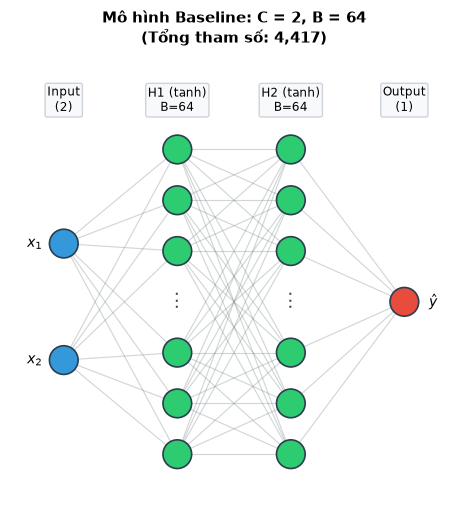

In [11]:
def count_mlp_params(input_dim, hidden_dims, output_dim=1):
    """Tính tổng số tham số huấn luyện (Weights + Biases) của mạng DynamicMLP."""
    dims = [input_dim] + list(hidden_dims) + [output_dim]
    return sum(dims[i] * dims[i+1] + dims[i+1] for i in range(len(dims) - 1))

def draw_single_mlp(ax, hidden_dims, input_dim=2, output_dim=1, activation='tanh', max_display_nodes=7, title_prefix=""):
    """Vẽ sơ đồ kiến trúc mạng DynamicMLP lên một subplot (ax)."""
    ax.axis('off')
    ax.set_aspect('equal')
    C = len(hidden_dims)
    
    display_dims = [input_dim] + [min(b, max_display_nodes) for b in hidden_dims] + [output_dim]
    truncated_flags = [False] + [b > max_display_nodes for b in hidden_dims] + [False]
    
    n_layers = len(display_dims)
    x_positions = np.linspace(0.12, 0.88, n_layers)
    
    node_coords = []
    for i, size in enumerate(display_dims):
        if size == 1:
            y_pos = [0.46]
        else:
            span = min(0.68, max(0.26, size * 0.105))
            y_pos = np.linspace(0.46 + span/2, 0.46 - span/2, size)
        node_coords.append([(x_positions[i], y) for y in y_pos])

    # 1. Vẽ các đường kết nối (Weights)
    for i in range(n_layers - 1):
        for idx1, (x1, y1) in enumerate(node_coords[i]):
            if truncated_flags[i] and idx1 == display_dims[i] // 2:
                continue
            for idx2, (x2, y2) in enumerate(node_coords[i + 1]):
                if truncated_flags[i + 1] and idx2 == display_dims[i + 1] // 2:
                    continue
                ax.plot([x1, x2], [y1, y2], color='#7f8c8d', alpha=0.35, lw=0.85, zorder=1)

    # 2. Vẽ các nơ-ron (Nodes)
    radius = 0.032 if n_layers <= 4 else (0.024 if n_layers <= 6 else 0.019)
    for i, coords in enumerate(node_coords):
        color = '#3498db' if i == 0 else ('#e74c3c' if i == n_layers - 1 else '#2ecc71')
        for j, (x, y) in enumerate(coords):
            if truncated_flags[i] and j == display_dims[i] // 2:
                ax.text(x, y, r'$\vdots$', fontsize=14, ha='center', va='center', fontweight='bold', color='#2c3e50')
                continue
                
            circle = plt.Circle((x, y), radius, color=color, ec='#2c3e50', lw=1.2, zorder=3)
            ax.add_patch(circle)
            
            if i == 0:
                ax.text(x - 0.065, y, f'$x_{j+1}$', fontsize=10, ha='center', va='center', fontweight='bold')
            elif i == n_layers - 1:
                ax.text(x + 0.065, y, r'$\hat{y}$', fontsize=10, ha='center', va='center', fontweight='bold')

        # Nhãn tên từng tầng
        if i == 0:
            lbl = "In\n(2)" if n_layers > 6 else "Input\n(2)"
        elif i == n_layers - 1:
            lbl = "Out\n(1)" if n_layers > 6 else "Output\n(1)"
        else:
            lbl = f"H{i}\n({hidden_dims[i-1]})" if n_layers > 6 else f"H{i} ({activation})\nB={hidden_dims[i-1]}"
        font_sz = 7.5 if n_layers > 6 else 8.5
        ax.text(x_positions[i], 0.91, lbl, fontsize=font_sz, ha='center', va='center',
                bbox=dict(boxstyle='round,pad=0.18', facecolor='#f8f9fa', edgecolor='#ced4da'))

    total_params = count_mlp_params(input_dim, hidden_dims, output_dim)
    B_str = str(hidden_dims[0]) if len(set(hidden_dims)) == 1 else str(hidden_dims)
    title = f"{title_prefix}C = {C}, B = {B_str}\n(Tổng tham số: {total_params:,})"
    ax.set_title(title, fontsize=10.5, fontweight='bold', pad=6)
    ax.set_xlim(0, 1)
    ax.set_ylim(0.02, 1.02)

# Vẽ kiến trúc mạng Baseline: 2 tầng ẩn, mỗi tầng 64 nơ-ron ([64, 64])
fig_base, ax_base = plt.subplots(figsize=(6.5, 5.2))
draw_single_mlp(ax_base, hidden_dims=[64, 64], activation='tanh', title_prefix="Mô hình Baseline: ")
plt.tight_layout()
plt.savefig('figures/02a_baseline_architecture.png', dpi=150, bbox_inches='tight')
plt.show()

### Huấn luyện mô hình Baseline và trực quan hóa kết quả dự đoán

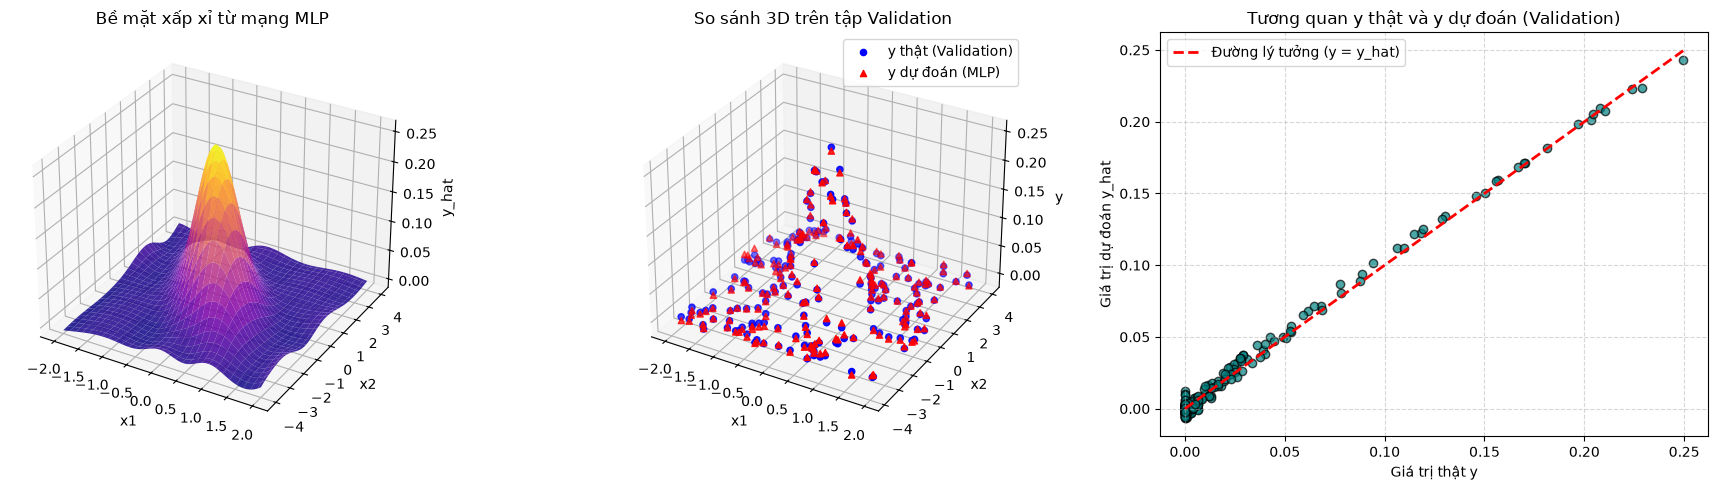

In [12]:
def visualize_predictions(model, mean, std, x_eval, y_eval, mu, cov, filename='figures/02_baseline_predictions.png', split_name='Validation'):
    """Vẽ bề mặt hàm xấp xỉ từ MLP và đồ thị so sánh y thật - y dự đoán trên tập đánh giá."""
    model.eval()
    
    # 1. Tạo lưới điểm để vẽ bề mặt xấp xỉ của MLP
    grid_x1, grid_x2 = np.meshgrid(np.linspace(-2, 2, 60), np.linspace(-4, 4, 60))
    grid_pts = np.vstack([grid_x1.ravel(), grid_x2.ravel()]).T
    grid_pts_norm = torch.tensor((grid_pts - mean) / std, dtype=torch.float32).to(DEVICE)
    
    with torch.no_grad():
        grid_preds = model(grid_pts_norm).cpu().numpy().reshape(grid_x1.shape)
        
    # Dự đoán trên tập đánh giá (Validation hoặc Test)
    x_ev_norm = torch.tensor((x_eval - mean) / std, dtype=torch.float32).to(DEVICE)
    with torch.no_grad():
        ev_preds = model(x_ev_norm).cpu().numpy().flatten()

    fig = plt.figure(figsize=(18, 5))

    # Đồ thị 1: Bề mặt xấp xỉ từ MLP
    ax1 = fig.add_subplot(1, 3, 1, projection='3d')
    ax1.plot_surface(grid_x1, grid_x2, grid_preds, cmap='plasma', edgecolor='none', alpha=0.85)
    ax1.set_title('Bề mặt xấp xỉ từ mạng MLP')
    ax1.set_xlabel('x1'); ax1.set_ylabel('x2'); ax1.set_zlabel('y_hat')

    # Đồ thị 2: So sánh điểm 3D trên tập đánh giá
    ax2 = fig.add_subplot(1, 3, 2, projection='3d')
    ax2.scatter(x_eval[:, 0], x_eval[:, 1], y_eval, color='blue', label=f'y thật ({split_name})', s=20)
    ax2.scatter(x_eval[:, 0], x_eval[:, 1], ev_preds, color='red', marker='^', label=f'y dự đoán (MLP)', s=20)
    ax2.set_title(f'So sánh 3D trên tập {split_name}')
    ax2.set_xlabel('x1'); ax2.set_ylabel('x2'); ax2.set_zlabel('y')
    ax2.legend()

    # Đồ thị 3: Tương quan y thật vs y dự đoán
    ax3 = fig.add_subplot(1, 3, 3)
    ax3.scatter(y_eval, ev_preds, color='teal', alpha=0.7, edgecolors='k')
    max_val = max(y_eval.max(), ev_preds.max())
    ax3.plot([0, max_val], [0, max_val], 'r--', lw=2, label='Đường lý tưởng (y = y_hat)')
    ax3.set_title(f'Tương quan y thật và y dự đoán ({split_name})')
    ax3.set_xlabel('Giá trị thật y'); ax3.set_ylabel('Giá trị dự đoán y_hat')
    ax3.legend(); ax3.grid(True, linestyle='--', alpha=0.5)

    plt.tight_layout()
    plt.savefig(filename, dpi=150)
    plt.show()

# Huấn luyện mô hình baseline trước khi trực quan hóa kết quả Validation.
baseline_res = train_and_evaluate_mlp(
    x_pool[:2000], y_pool[:2000], x_val, y_val, x_test, y_test,
    hidden_dims=[64], activation='tanh',
    lr=0.005, batch_size=32, epochs=150,
    seed=42, exp_name='baseline', save_log=True,
    evaluate_test=False
)

visualize_predictions(baseline_res['model'], baseline_res['mean'], baseline_res['std'], x_val, y_val, mu, cov, split_name='Validation')

## 3. Ba nhóm thực nghiệm bắt buộc A, B, C (Mục 4)

Chạy lặp qua 3 `SEEDS = [42, 100, 2026]` cho mỗi cấu hình để tính giá trị **Trung bình (Mean) $\pm$ Độ lệch chuẩn (Std)**.

### 3.1. Thực nghiệm A: Khảo sát quy mô dữ liệu huấn luyện ($A = 200, 400, 600, 800, 1000, 1200, 1400, 1600, 1800, 2000$)

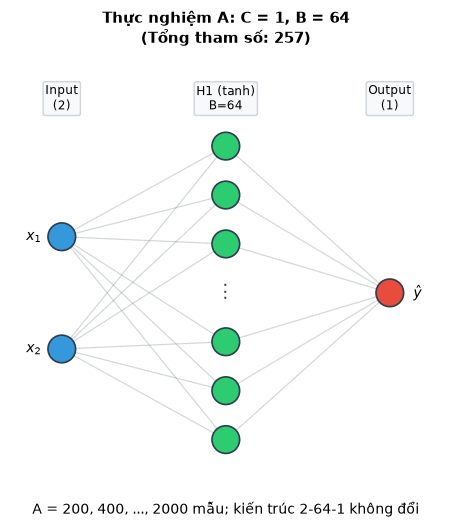

In [13]:
# A chỉ thay đổi số mẫu; kiến trúc 2-64-1 được giữ cố định.
fig_A, ax_A = plt.subplots(figsize=(7, 5.3))
draw_single_mlp(ax_A, hidden_dims=[64], activation='tanh',
                title_prefix="Thực nghiệm A: ")
fig_A.text(0.5, 0.02, "A = 200, 400, ..., 2000 mẫu; kiến trúc 2-64-1 không đổi",
           ha='center', fontsize=10)
fig_A.tight_layout(rect=[0, 0.05, 1, 1])
fig_A.savefig('figures/03a_experiment_A_neurons.png', dpi=150, bbox_inches='tight')
plt.show()


In [14]:
def plot_experiment_loss(letter, config_col, label):
    """Plot one experiment's train and validation MSE, averaged across three seeds."""
    history = pd.read_csv(f'logs/experiment_{letter}_loss.csv')
    required = {'epoch', 'train_mse', 'val_mse', config_col, 'seed'}
    if not required.issubset(history.columns):
        raise ValueError(f"Experiment {letter} log is missing columns: {required - set(history.columns)}")
    mean_loss = history.groupby([config_col, 'epoch'], as_index=False)[
        ['train_mse', 'val_mse']].mean()
    configs = sorted(mean_loss[config_col].unique())
    colors = plt.get_cmap('turbo', len(configs))
    fig, axes = plt.subplots(1, 2, figsize=(16, 5.5), sharex=True)
    for ax, metric, split in zip(axes, ('train_mse', 'val_mse'), ('Train', 'Validation')):
        for idx, value in enumerate(configs):
            curve = mean_loss[mean_loss[config_col] == value]
            ax.plot(curve['epoch'], curve[metric], color=colors(idx),
                    linewidth=1.7, label=f'{label} = {value}')
        ax.set_title(f'{split} loss')
        ax.set_xlabel('Epoch')
        ax.set_ylabel('MSE (log scale)')
        ax.set_yscale('log')
        ax.grid(True, which='both', linestyle='--', alpha=0.3)
        ax.legend(ncol=2 if len(configs) > 8 else 1, fontsize=8)
    fig.suptitle(f'Experiment {letter}: loss by epoch (mean of 3 seeds)',
                 fontsize=14, fontweight='bold')
    fig.tight_layout()
    fig.savefig(f'figures/experiment_{letter}_loss.png', dpi=150, bbox_inches='tight')
    plt.show()


--- ĐANG CHẠY THỰC NGHIỆM A (QUY MÔ DỮ LIỆU) ---
Hoàn thành A = 200
Hoàn thành A = 400
Hoàn thành A = 600
Hoàn thành A = 800
Hoàn thành A = 1000
Hoàn thành A = 1200
Hoàn thành A = 1400
Hoàn thành A = 1600
Hoàn thành A = 1800
Hoàn thành A = 2000


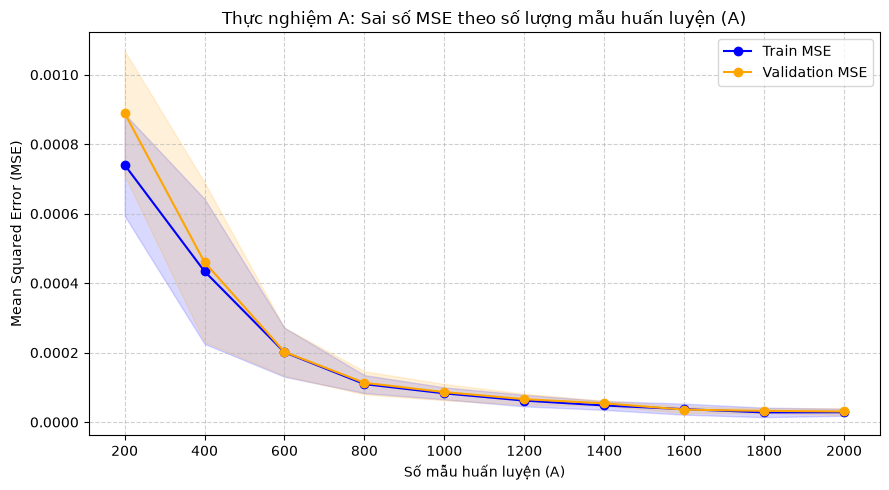

train_mse             val_mse          
               mean       std      mean       std
A_samples                                        
200        0.000741  0.000147  0.000890  0.000180
400        0.000434  0.000209  0.000460  0.000229
600        0.000201  0.000071  0.000202  0.000069
800        0.000109  0.000026  0.000113  0.000033
1000       0.000083  0.000017  0.000086  0.000023
1200       0.000062  0.000017  0.000066  0.000016
1400       0.000048  0.000013  0.000054  0.000008
1600       0.000037  0.000016  0.000036  0.000010
1800       0.000028  0.000014  0.000032  0.000007
2000       0.000028  0.000010  0.000031  0.000010

In [15]:
SEEDS = [42, 100, 2026]

def run_experiment_A(x_pool, y_pool, x_val, y_val):
    print("--- ĐANG CHẠY THỰC NGHIỆM A (QUY MÔ DỮ LIỆU) ---")
    sizes = list(range(200, 2001, 200))
    records = []
    loss_histories = []

    for A in sizes:
        for s in SEEDS:
            res = train_and_evaluate_mlp(
                x_pool[:A], y_pool[:A], x_val, y_val, None, None,
                hidden_dims=[64], activation='tanh', lr=0.005, batch_size=32, epochs=120,
                seed=s, exp_name=f"ExpA_size{A}", save_log=False
            )
            history = res['history'].copy()
            history['A_samples'] = A
            history['seed'] = s
            loss_histories.append(history)
            records.append({
                'A_samples': A, 'seed': s,
                'train_mse': res['train']['MSE'],
                'val_mse': res['val']['MSE'],
                'val_rmse': res['val']['RMSE'],
                'val_mae': res['val']['MAE'],
                'train_time': res['train_time']
            })
        print(f"Hoàn thành A = {A}")

    pd.concat(loss_histories, ignore_index=True).to_csv('logs/experiment_A_loss.csv', index=False)
    df = pd.DataFrame(records)
    df.to_csv('logs/experiment_A_raw.csv', index=False)
    summary = df.groupby('A_samples').agg(['mean', 'std'])
    summary.to_csv('logs/experiment_A_summary.csv')

    # Vẽ đồ thị sai số theo A
    plt.figure(figsize=(9, 5))
    for split, color, label in [('train_mse', 'blue', 'Train MSE'), ('val_mse', 'orange', 'Validation MSE')]:
        m = df.groupby('A_samples')[split].mean()
        sd = df.groupby('A_samples')[split].std()
        plt.plot(sizes, m, marker='o', color=color, label=label)
        plt.fill_between(sizes, m - sd, m + sd, color=color, alpha=0.15)
    plt.title("Thực nghiệm A: Sai số MSE theo số lượng mẫu huấn luyện (A)")
    plt.xlabel("Số mẫu huấn luyện (A)"); plt.ylabel("Mean Squared Error (MSE)")
    plt.xticks(sizes); plt.grid(True, linestyle='--', alpha=0.6); plt.legend()
    plt.tight_layout()
    plt.savefig('figures/03_experiment_A_samples.png', dpi=150)
    plt.show()
    return summary

summary_A = run_experiment_A(x_pool, y_pool, x_val, y_val)
display(summary_A[['train_mse', 'val_mse']])

#### Loss by epoch - Experiment A

Train and validation MSE are averaged across three seeds for each configuration.


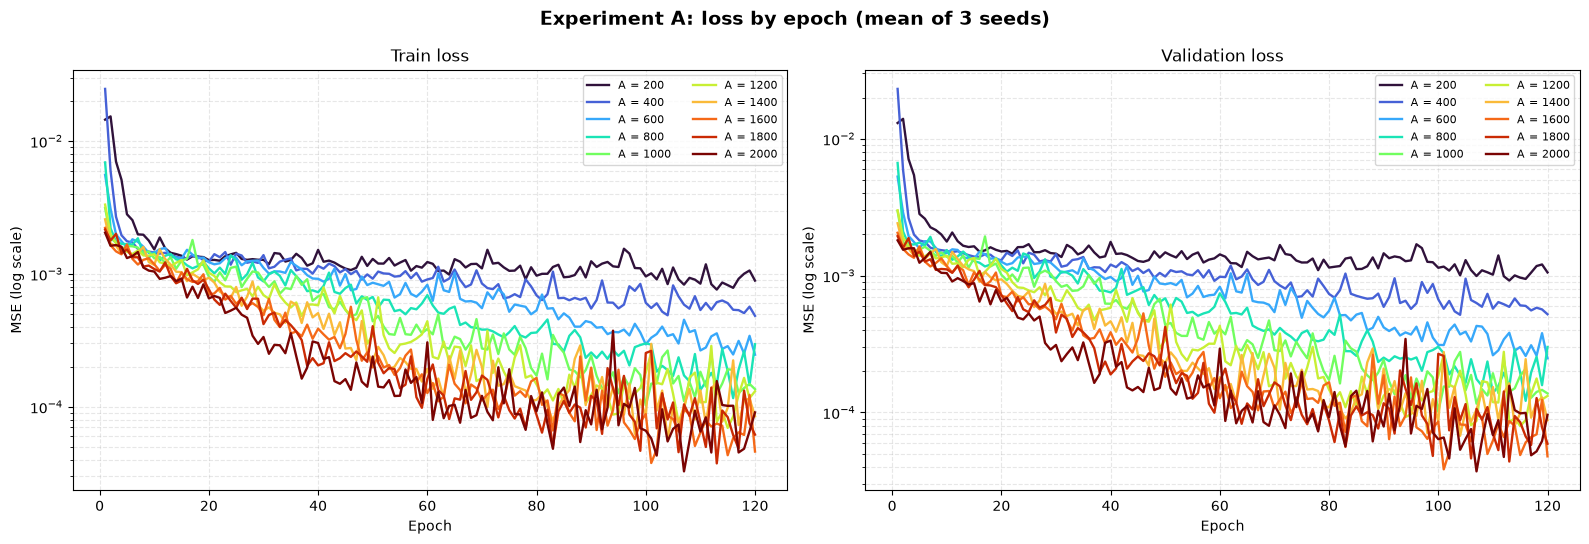

In [16]:
plot_experiment_loss('A', 'A_samples', 'A')


### Phân tích kết quả A (tự động sau khi chạy)

- **Cách đọc:** theo dõi Validation MSE (đường cam); Train MSE dùng để đối chiếu mức độ khớp. Dải tô thể hiện độ lệch chuẩn giữa 3 seeds.
- **Diễn giải:** nếu Validation MSE giảm khi A tăng, dữ liệu nhiều hơn giúp mô hình tổng quát hóa tốt hơn trong phạm vi khảo sát. Nếu giảm rồi gần như ổn định, có thể số mẫu bổ sung đem lại lợi ích nhỏ dần. Nếu Train MSE giảm nhưng Validation MSE tăng, cần xem xét dấu hiệu overfitting/biến động theo seed.
- **Kết quả thực tế:** cell kế tiếp tự in A có Validation MSE trung bình thấp nhất và mức thay đổi từ A nhỏ nhất đến lớn nhất. Không dùng Test để chọn A.

In [17]:
# Tóm tắt định lượng A dựa trên Validation (không dùng Test)
a_val = summary_A['val_mse']['mean']
a_best = int(a_val.idxmin())
a_first, a_last = float(a_val.iloc[0]), float(a_val.iloc[-1])
delta_pct = (a_last - a_first) / max(abs(a_first), 1e-12) * 100
print(f"A tốt nhất theo Validation MSE: {a_best} mẫu (mean={a_val.loc[a_best]:.6g}, std={summary_A['val_mse']['std'].loc[a_best]:.6g})")
print(f"Validation MSE từ A={a_val.index[0]} đến A={a_val.index[-1]} thay đổi {delta_pct:+.2f}%")
print("Lưu ý: đây là mô tả xu hướng; lựa chọn cuối cùng cần cân nhắc độ ổn định (std) và chi phí huấn luyện.")

A tốt nhất theo Validation MSE: 2000 mẫu (mean=3.05482e-05, std=9.78302e-06)
Validation MSE từ A=200 đến A=2000 thay đổi -96.57%
Lưu ý: đây là mô tả xu hướng; lựa chọn cuối cùng cần cân nhắc độ ổn định (std) và chi phí huấn luyện.


### 3.2. Thực nghiệm B: Khảo sát độ rộng tầng ẩn ($B = 1, 2, \dots, 10, 16, 32, 64, 128$)

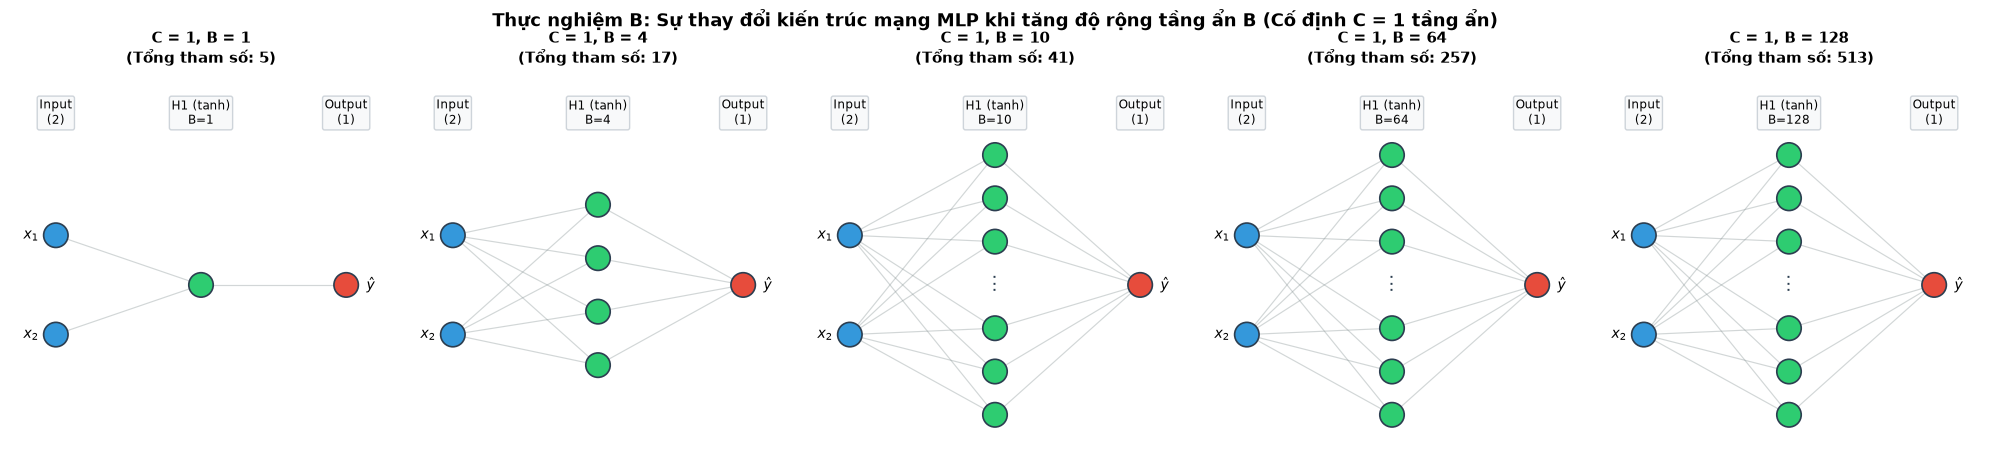

In [18]:
# Trực quan hóa sự thay đổi kiến trúc mạng MLP trong Thực nghiệm B (Cố định C = 1, thay đổi độ rộng B)
B_samples = [1, 4, 10, 64, 128]
fig_B, axes_B = plt.subplots(1, len(B_samples), figsize=(20, 4.5))
for ax, B in zip(axes_B, B_samples):
    draw_single_mlp(ax, hidden_dims=[B], activation='tanh')
plt.suptitle("Thực nghiệm B: Sự thay đổi kiến trúc mạng MLP khi tăng độ rộng tầng ẩn B (Cố định C = 1 tầng ẩn)", 
             fontsize=13, fontweight='bold', y=1.02)
plt.tight_layout()
plt.savefig('figures/04a_experiment_B_architectures.png', dpi=150, bbox_inches='tight')
plt.show()

--- ĐANG CHẠY THỰC NGHIỆM B (ĐỘ RỘNG TẦNG ẨN) ---
Hoàn thành B = 1
Hoàn thành B = 2
Hoàn thành B = 3
Hoàn thành B = 4
Hoàn thành B = 5
Hoàn thành B = 6
Hoàn thành B = 7
Hoàn thành B = 8
Hoàn thành B = 9
Hoàn thành B = 10
Hoàn thành B = 16
Hoàn thành B = 32
Hoàn thành B = 64
Hoàn thành B = 128


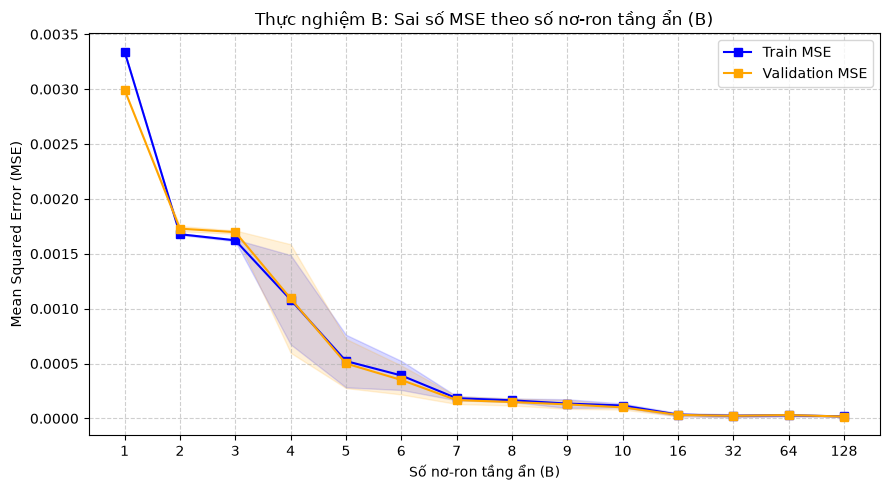

train_mse                 val_mse              
             mean           std      mean           std
B_nodes                                                
1        0.003342  1.045710e-07  0.002992  3.249339e-07
2        0.001678  7.007400e-06  0.001729  2.382430e-05
3        0.001622  8.057356e-06  0.001697  1.535346e-05
4        0.001081  4.070316e-04  0.001092  4.946071e-04
5        0.000523  2.397779e-04  0.000500  2.239034e-04
6        0.000391  1.322982e-04  0.000350  1.319760e-04
7        0.000184  1.903090e-05  0.000167  3.562618e-05
8        0.000165  1.619271e-05  0.000149  3.109567e-05
9        0.000135  3.962313e-05  0.000128  4.033615e-05
10       0.000118  1.796540e-05  0.000101  2.000805e-05
16       0.000034  1.448693e-05  0.000032  1.334996e-05
32       0.000024  1.353840e-05  0.000024  9.535062e-06
64       0.000028  1.018769e-05  0.000031  9.783021e-06
128      0.000018  5.161636e-06  0.000017  3.362232e-06

In [19]:
def run_experiment_B(x_pool, y_pool, x_val, y_val):
    print("--- ĐANG CHẠY THỰC NGHIỆM B (ĐỘ RỘNG TẦNG ẨN) ---")
    hidden_nodes_list = list(range(1, 11)) + [16, 32, 64, 128]
    records = []
    loss_histories = []

    for B in hidden_nodes_list:
        for s in SEEDS:
            res = train_and_evaluate_mlp(
                x_pool[:2000], y_pool[:2000], x_val, y_val, None, None,
                hidden_dims=[B], activation='tanh', lr=0.005, batch_size=32, epochs=120,
                seed=s, exp_name=f"ExpB_nodes{B}", save_log=False
            )
            history = res['history'].copy()
            history['B_nodes'] = B
            history['seed'] = s
            loss_histories.append(history)
            records.append({
                'B_nodes': B, 'seed': s,
                'train_mse': res['train']['MSE'], 'val_mse': res['val']['MSE'],
                'train_time': res['train_time']
            })
        print(f"Hoàn thành B = {B}")

    pd.concat(loss_histories, ignore_index=True).to_csv('logs/experiment_B_loss.csv', index=False)
    df = pd.DataFrame(records)
    df.to_csv('logs/experiment_B_raw.csv', index=False)
    summary = df.groupby('B_nodes').agg(['mean', 'std'])
    summary.to_csv('logs/experiment_B_summary.csv')

    # Vẽ đồ thị sai số theo B
    plt.figure(figsize=(9, 5))
    x_idx = range(len(hidden_nodes_list))
    for split, color, label in [('train_mse', 'blue', 'Train MSE'), ('val_mse', 'orange', 'Validation MSE')]:
        m = df.groupby('B_nodes')[split].mean().values
        sd = df.groupby('B_nodes')[split].std().values
        plt.plot(x_idx, m, marker='s', color=color, label=label)
        plt.fill_between(x_idx, m - sd, m + sd, color=color, alpha=0.15)
    plt.title("Thực nghiệm B: Sai số MSE theo số nơ-ron tầng ẩn (B)")
    plt.xlabel("Số nơ-ron tầng ẩn (B)"); plt.ylabel("Mean Squared Error (MSE)")
    plt.xticks(x_idx, hidden_nodes_list); plt.grid(True, linestyle='--', alpha=0.6); plt.legend()
    plt.tight_layout()
    plt.savefig('figures/04_experiment_B_width.png', dpi=150)
    plt.show()
    return summary

summary_B = run_experiment_B(x_pool, y_pool, x_val, y_val)
display(summary_B[['train_mse', 'val_mse']])

#### Loss by epoch - Experiment B

Train and validation MSE are averaged across three seeds for each configuration.


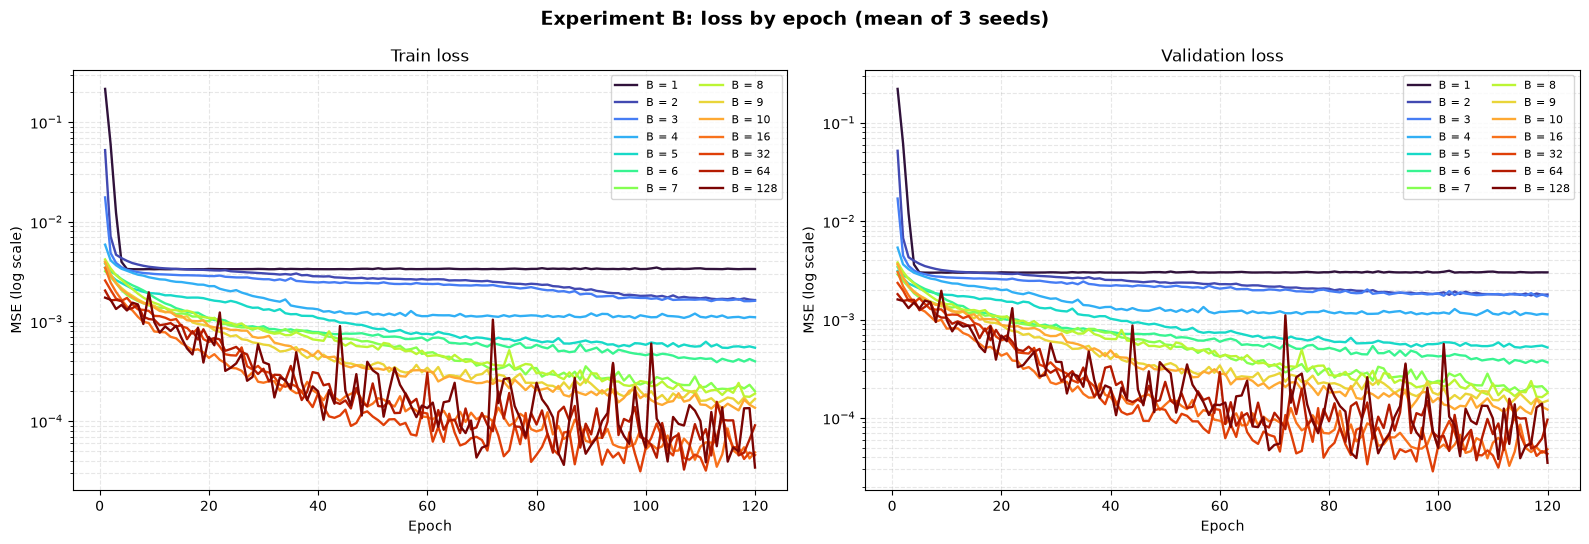

In [20]:
plot_experiment_loss('B', 'B_nodes', 'B')


### Phân tích kết quả B (tự động sau khi chạy)

- **Underfitting:** B nhỏ có thể khiến Train và Validation MSE cùng cao, mô hình chưa đủ khả năng biểu diễn hàm.
- **Cải thiện:** khi tăng B, cả hai sai số có thể giảm do tăng năng lực mô hình.
- **Overfitting/độ phức tạp:** nếu Train MSE tiếp tục giảm nhưng Validation MSE không giảm hoặc tăng, mạng rộng hơn không còn cải thiện khả năng tổng quát hóa; cũng cần xét độ lệch chuẩn giữa seeds.
- **Kết quả thực tế:** cell kế tiếp tìm B có Validation MSE trung bình thấp nhất. Chọn B theo Validation, không theo Test.

In [21]:
# Tóm tắt định lượng B dựa trên Validation
b_val = summary_B['val_mse']['mean']
b_best = int(b_val.idxmin())
print(f"B tốt nhất theo Validation MSE: {b_best} neuron (mean={b_val.loc[b_best]:.6g}, std={summary_B['val_mse']['std'].loc[b_best]:.6g})")
print(f"Train MSE tại B tốt nhất: {summary_B['train_mse']['mean'].loc[b_best]:.6g}")
print("So sánh Train–Validation tại B tốt nhất và các B lân cận để nhận xét mức khớp/khả năng tổng quát hóa.")

B tốt nhất theo Validation MSE: 128 neuron (mean=1.69324e-05, std=3.36223e-06)
Train MSE tại B tốt nhất: 1.84136e-05
So sánh Train–Validation tại B tốt nhất và các B lân cận để nhận xét mức khớp/khả năng tổng quát hóa.


### 3.3. Thực nghiệm C: Khảo sát độ sâu mạng MLP ($C = 1, 2, 3, 4, 6, 8$ tầng ẩn)

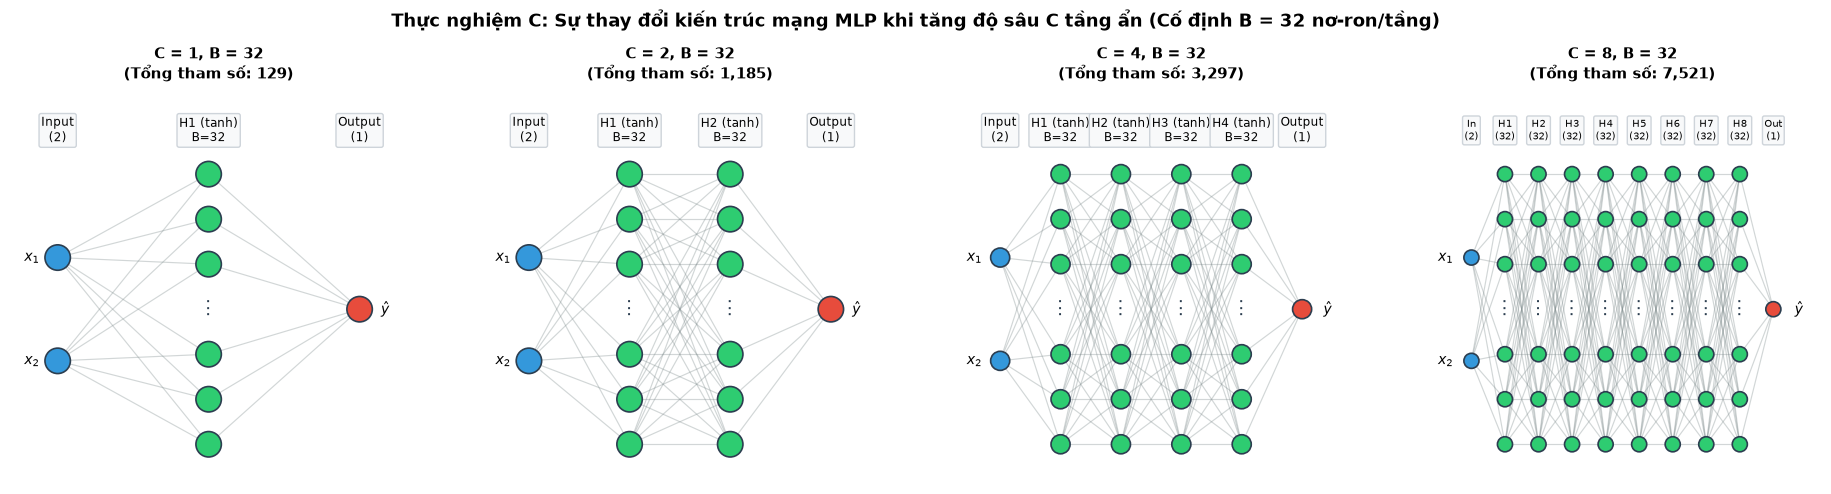

In [22]:
# Trực quan hóa sự thay đổi kiến trúc mạng MLP trong Thực nghiệm C (Cố định B = 32, thay đổi số tầng ẩn C)
C_samples = [1, 2, 4, 8]
fig_C, axes_C = plt.subplots(1, len(C_samples), figsize=(19, 4.8))
for ax, C in zip(axes_C, C_samples):
    draw_single_mlp(ax, hidden_dims=[32]*C, activation='tanh')
plt.suptitle("Thực nghiệm C: Sự thay đổi kiến trúc mạng MLP khi tăng độ sâu C tầng ẩn (Cố định B = 32 nơ-ron/tầng)", 
             fontsize=13, fontweight='bold', y=1.02)
plt.tight_layout()
plt.savefig('figures/05a_experiment_C_architectures.png', dpi=150, bbox_inches='tight')
plt.show()

--- ĐANG CHẠY THỰC NGHIỆM C (ĐỘ SÂU MẠNG MLP) ---
Hoàn thành C = 1
Hoàn thành C = 2
Hoàn thành C = 3
Hoàn thành C = 4
Hoàn thành C = 6
Hoàn thành C = 8


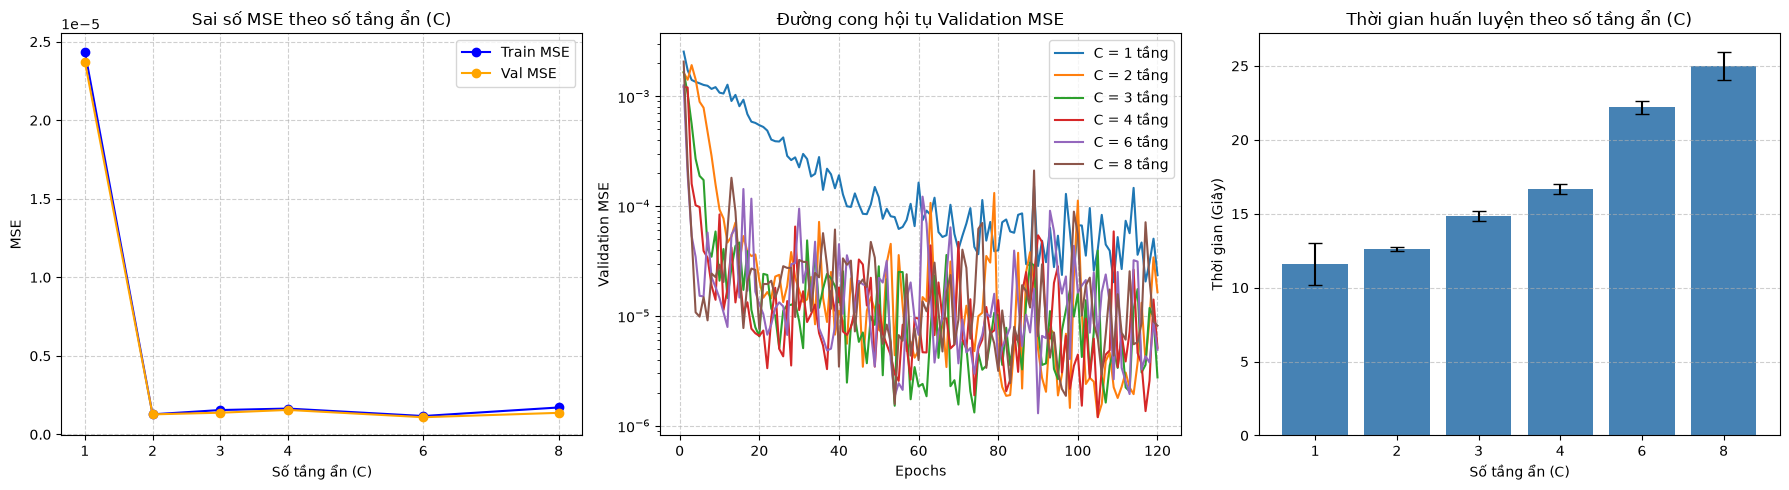

train_mse                 val_mse               train_time          
              mean           std      mean           std       mean       std
C_layers                                                                     
1         0.000024  1.353840e-05  0.000024  9.535062e-06  11.596012  1.447219
2         0.000001  2.083285e-07  0.000001  2.851223e-07  12.594062  0.130244
3         0.000002  2.861317e-07  0.000001  2.774759e-07  14.873107  0.336980
4         0.000002  5.811540e-08  0.000002  3.138902e-07  16.684152  0.334833
6         0.000001  1.070045e-07  0.000001  1.825066e-07  22.207513  0.427518
8         0.000002  5.894078e-07  0.000001  2.557614e-07  24.979281  0.930047

In [23]:
def run_experiment_C(x_pool, y_pool, x_val, y_val):
    print("--- ĐANG CHẠY THỰC NGHIỆM C (ĐỘ SÂU MẠNG MLP) ---")
    depths = [1, 2, 3, 4, 6, 8]
    records = []
    loss_histories = []
    convergence_curves = {}

    for C in depths:
        h_dims = [32] * C  # Mỗi tầng ẩn giữ cố định 32 nơ-ron
        for s in SEEDS:
            res = train_and_evaluate_mlp(
                x_pool[:2000], y_pool[:2000], x_val, y_val, None, None,
                hidden_dims=h_dims, activation='tanh', lr=0.005, batch_size=32, epochs=120,
                seed=s, exp_name=f"ExpC_layers{C}", save_log=(s == SEEDS[0])
            )
            if s == SEEDS[0]:
                convergence_curves[C] = res['history']['val_mse'].values
            history = res['history'].copy()
            history['C_layers'] = C
            history['seed'] = s
            loss_histories.append(history)
            records.append({
                'C_layers': C, 'seed': s,
                'train_mse': res['train']['MSE'], 'val_mse': res['val']['MSE'],
                'train_time': res['train_time']
            })
        print(f"Hoàn thành C = {C}")

    pd.concat(loss_histories, ignore_index=True).to_csv('logs/experiment_C_loss.csv', index=False)
    df = pd.DataFrame(records)
    df.to_csv('logs/experiment_C_raw.csv', index=False)
    summary = df.groupby('C_layers').agg(['mean', 'std'])
    summary.to_csv('logs/experiment_C_summary.csv')

    # Vẽ đồ thị Train/Validation Error, Thời gian huấn luyện và Tốc độ hội tụ
    fig, axes = plt.subplots(1, 3, figsize=(18, 5))

    # 1. MSE theo số tầng C
    for split, color, label in [('train_mse', 'blue', 'Train MSE'), ('val_mse', 'orange', 'Val MSE')]:
        m = df.groupby('C_layers')[split].mean()
        axes[0].plot(depths, m, marker='o', color=color, label=label)
    axes[0].set_title("Sai số MSE theo số tầng ẩn (C)")
    axes[0].set_xlabel("Số tầng ẩn (C)"); axes[0].set_ylabel("MSE")
    axes[0].set_xticks(depths); axes[0].grid(True, linestyle='--', alpha=0.6); axes[0].legend()

    # 2. Đường cong hội tụ Validation Loss theo Epoch
    for C, curve in convergence_curves.items():
        axes[1].plot(range(1, len(curve) + 1), curve, label=f"C = {C} tầng")
    axes[1].set_title("Đường cong hội tụ Validation MSE")
    axes[1].set_xlabel("Epochs"); axes[1].set_ylabel("Validation MSE")
    axes[1].set_yscale('log'); axes[1].grid(True, linestyle='--', alpha=0.6); axes[1].legend()

    # 3. Thời gian huấn luyện
    t_mean = df.groupby('C_layers')['train_time'].mean()
    t_std = df.groupby('C_layers')['train_time'].std()
    axes[2].bar([str(c) for c in depths], t_mean, yerr=t_std, color='steelblue', capsize=5)
    axes[2].set_title("Thời gian huấn luyện theo số tầng ẩn (C)")
    axes[2].set_xlabel("Số tầng ẩn (C)"); axes[2].set_ylabel("Thời gian (Giây)")
    axes[2].grid(True, axis='y', linestyle='--', alpha=0.6)

    plt.tight_layout()
    plt.savefig('figures/05_experiment_C_depth.png', dpi=150)
    plt.show()
    return summary

summary_C = run_experiment_C(x_pool, y_pool, x_val, y_val)
display(summary_C[['train_mse', 'val_mse', 'train_time']])

#### Loss by epoch - Experiment C

Train and validation MSE are averaged across three seeds for each configuration.


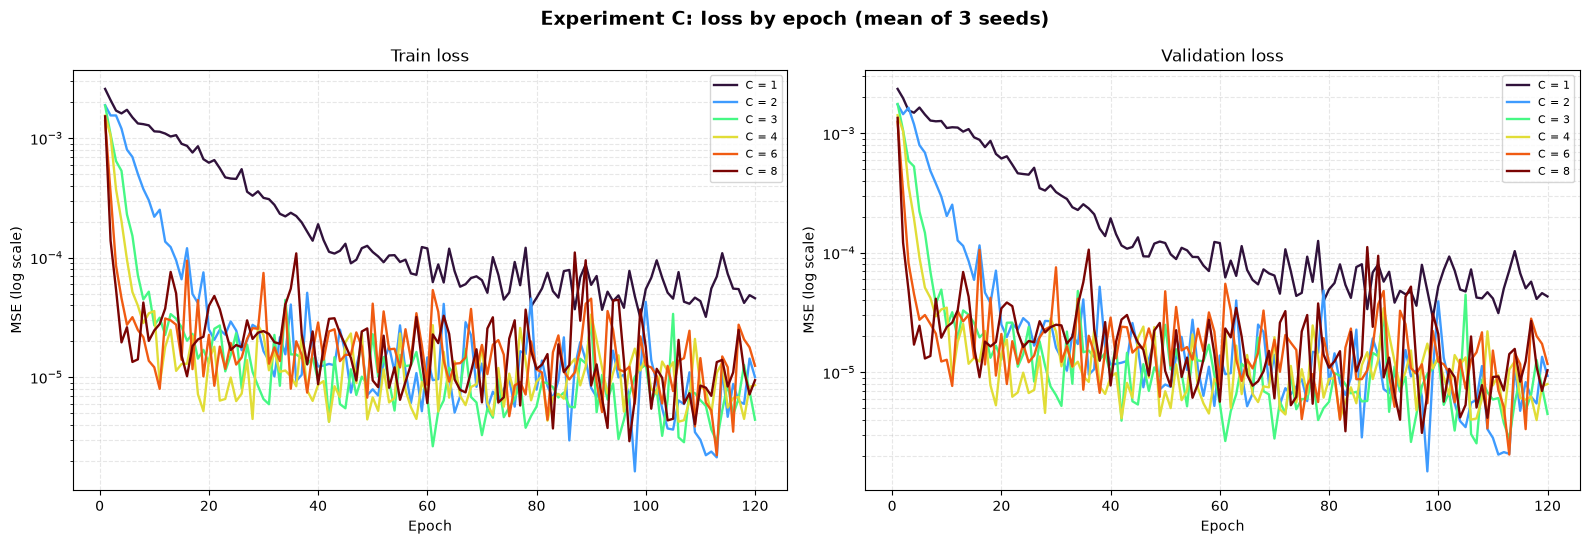

In [24]:
plot_experiment_loss('C', 'C_layers', 'C')


### Phân tích kết quả C (tự động sau khi chạy)

- **Độ sâu và sai số:** so sánh Validation MSE trung bình giữa các C. Mạng sâu hơn không mặc nhiên tốt hơn; nhiều tầng có thể tăng năng lực biểu diễn nhưng cũng khiến tối ưu khó hơn.
- **Hội tụ:** đường Validation MSE theo epoch cho biết loss giảm nhanh/chậm, có ổn định hay dao động. Checkpoint được chọn tại epoch có Validation Loss thấp nhất.
- **Chi phí:** thời gian huấn luyện thường tăng theo độ sâu; cân nhắc đánh đổi giữa sai số Validation và thời gian.
- **Kết quả thực tế:** cell kế tiếp tổng hợp C tốt nhất theo Validation MSE và thời gian trung bình. Test vẫn chưa được dùng ở nhóm C.

In [25]:
# Tóm tắt định lượng C dựa trên Validation và thời gian
c_val = summary_C['val_mse']['mean']
c_best = int(c_val.idxmin())
print(f"C tốt nhất theo Validation MSE: {c_best} tầng (mean={c_val.loc[c_best]:.6g}, std={summary_C['val_mse']['std'].loc[c_best]:.6g})")
print(f"Thời gian train trung bình tại C tốt nhất: {summary_C['train_time']['mean'].loc[c_best]:.2f} giây")
print("\nBảng đánh đổi Validation MSE – thời gian:")
display(pd.DataFrame({
    'val_mse_mean': summary_C['val_mse']['mean'],
    'val_mse_std': summary_C['val_mse']['std'],
    'train_time_mean_s': summary_C['train_time']['mean']
}).sort_values('val_mse_mean'))

C tốt nhất theo Validation MSE: 6 tầng (mean=1.09377e-06, std=1.82507e-07)
Thời gian train trung bình tại C tốt nhất: 22.21 giây

Bảng đánh đổi Validation MSE – thời gian:


,val_mse_mean,val_mse_std,train_time_mean_s
C_layers,,,
6,0.000001,1.825066e-07,22.207513
2,0.000001,2.851223e-07,12.594062
8,0.000001,2.557614e-07,24.979281
3,0.000001,2.774759e-07,14.873107
4,0.000002,3.138902e-07,16.684152
1,0.000024,9.535062e-06,11.596012


## 4. Đánh giá cuối cùng trên Test (chỉ một lần)

Sau khi hoàn thành A/B/C, chọn cấu hình dựa trên **Validation MSE** (và cân nhắc độ ổn định/thời gian). Điền cấu hình đã chọn vào `FINAL_HIDDEN_DIMS`; không chọn dựa trên Test. Cell sau huấn luyện cấu hình cuối và đánh giá Test đúng một lần.

Final model: hidden_dims=[32, 32], activation=tanh
Best epoch (Validation): 105
Test MSE : 0.00000149
Test RMSE: 0.00121904
Test MAE : 0.00094537


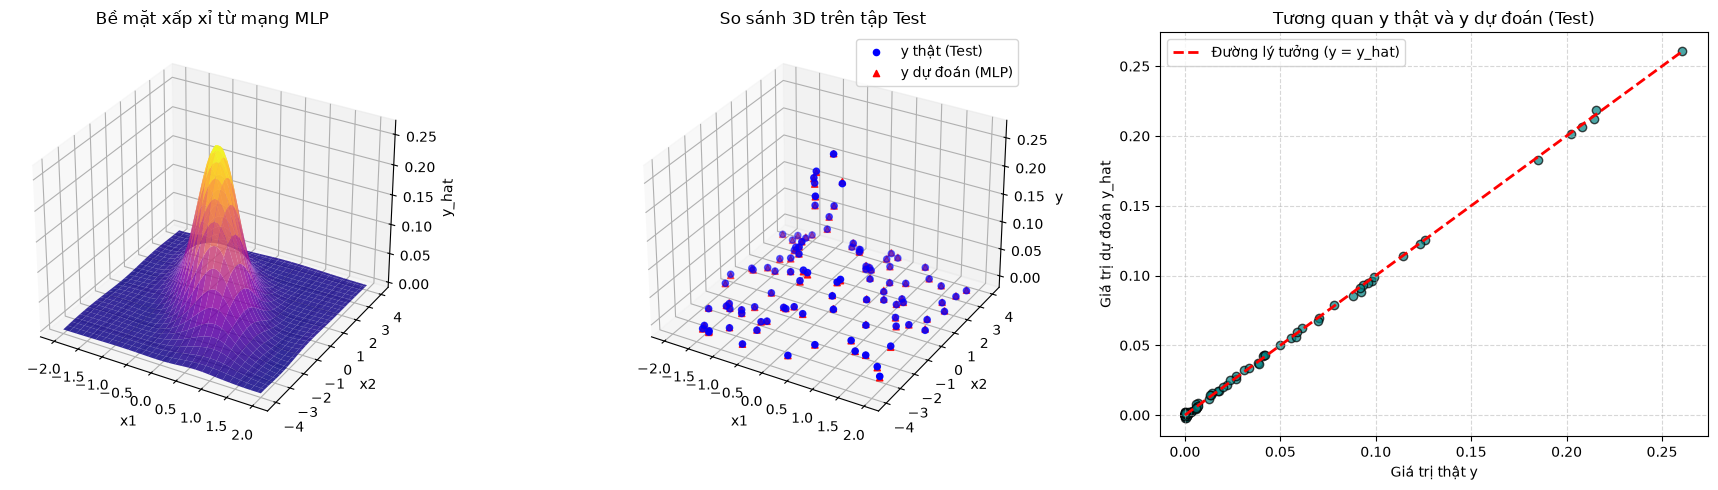

In [26]:
# Chọn cấu hình tối ưu từ Validation của A/B/C: C = 2 tầng ẩn, mỗi tầng 32 nơ-ron (cân bằng tốt nhất giữa MSE và thời gian)
FINAL_HIDDEN_DIMS = [32, 32]
FINAL_ACTIVATION = 'tanh'

final_res = train_and_evaluate_mlp(
    x_pool[:2000], y_pool[:2000], x_val, y_val, x_test, y_test,
    hidden_dims=FINAL_HIDDEN_DIMS, activation=FINAL_ACTIVATION,
    lr=0.005, batch_size=32, epochs=120,
    seed=42, exp_name='final_selected_model', save_log=True,
    evaluate_test=True
)

print(f"Final model: hidden_dims={FINAL_HIDDEN_DIMS}, activation={FINAL_ACTIVATION}")
print(f"Best epoch (Validation): {final_res['best_epoch']}")
print(f"Test MSE : {final_res['test']['MSE']:.8f}")
print(f"Test RMSE: {final_res['test']['RMSE']:.8f}")
print(f"Test MAE : {final_res['test']['MAE']:.8f}")

visualize_predictions(final_res['model'], final_res['mean'], final_res['std'],
                      x_test, y_test, mu, cov,
                      filename='figures/06_final_test_predictions.png',
                      split_name='Test')